MUHAMMAD YUSUF 2411512010 PEMOGRAMAN PARALEL B

1. BANK ACCOUNT RACE CONDITION

In [ ]:
import threading

saldo_tanpa_lock = 1000000

def transaksi_tanpa_lock():
    global saldo_tanpa_lock
    for _ in range(10000):
        
        temp = saldo_tanpa_lock
        temp -= 1
        saldo_tanpa_lock = temp
        
        temp = saldo_tanpa_lock
        temp += 1
        saldo_tanpa_lock = temp

threads_tl = [threading.Thread(target=transaksi_tanpa_lock) for _ in range(10)]
for t in threads_tl: t.start()
for t in threads_tl: t.join()

print(f"Saldo akhir TANPA lock: {saldo_tanpa_lock}")


saldo_dengan_lock = 1000000
lock = threading.Lock()

def transaksi_dengan_lock():
    global saldo_dengan_lock
    for _ in range(10000):
        with lock:
            saldo_dengan_lock -= 1
            saldo_dengan_lock += 1

threads_dl = [threading.Thread(target=transaksi_dengan_lock) for _ in range(10)]
for t in threads_dl: t.start()
for t in threads_dl: t.join()

print(f"Saldo akhir DENGAN lock: {saldo_dengan_lock}")

Saldo akhir TANPA lock: 1000000
Saldo akhir DENGAN lock: 1000000


Pada skenario tanpa lock, sehaarusnya saldo_akhir hampir selalu tidak kembali ke 1.000.000 karena terjadinya race condition (thread membaca dan memodifikasi variabel secara bersamaan sebelum thread lain selesai). Tetapi karena kecepatan CPU modern, hasil run juga tetap menghasilkan angka yang sama dengan menggunakan lock(). Dengan Lock(), eksekusi penambahan/pengurangan terjadi secara atomik (satu per satu), sehingga saldo selalu konsisten 1.000.000

Penjelasan Kode :

import threading: Mengimpor modul bawaan Python untuk menjalankan beberapa thread secara bersamaan.

saldo_tanpa_lock = 1000000: Mendeklarasikan variabel global yang menyimpan saldo awal.

def transaksi_tanpa_lock():: Mendefinisikan fungsi yang akan dijalankan oleh setiap thread.

global saldo_tanpa_lock: Memberitahu fungsi untuk memodifikasi variabel saldo_tanpa_lock yang ada di luar fungsi.

for _ in range(10000):: Memulai perulangan sebanyak 10.000 kali untuk setiap thread.

temp = saldo_tanpa_lock hingga saldo_tanpa_lock = temp: Menyimulasikan operasi tarik (kurang 1) dan setor (tambah 1) melalui variabel sementara (temp). Pemisahan baris ini sengaja dilakukan untuk memperbesar peluang terjadinya race condition.

threads_tl = [threading.Thread(target=transaksi_tanpa_lock) for _ in range(10)]: Membuat list comprehension berisi 10 objek thread, masing-masing ditugaskan menjalankan fungsi transaksi_tanpa_lock.

for t in threads_tl: t.start(): Memulai/menjalankan ke-10 thread tersebut secara bersamaan.

for t in threads_tl: t.join(): Memblokir program utama agar menunggu sampai seluruh 10 thread selesai bekerja sebelum melanjutkan ke baris berikutnya.

print(...): Menampilkan saldo akhir ke layar.

lock = threading.Lock(): Membuat objek kunci (lock) untuk mencegah lebih dari satu thread mengakses blok kode tertentu secara bersamaan.

with lock:: Blok kode di dalam with lock: akan dikunci. Jika ada thread lain yang ingin mengeksekusi blok ini, ia harus mengantre sampai thread sebelumnya selesai.

2. PRODUSER-KONSUMER DENGAN BANYAK KONSUMER

In [8]:
import threading
import queue
import time

def producer(q):
    for i in range(10):
        item = f"Data-{i}"
        q.put(item)
        print(f"[Producer] Menaruh {item}")
        time.sleep(0.1)
        
    # Mengirim sinyal berhenti (None) sebanyak jumlah consumer
    for _ in range(3):
        q.put(None)

def consumer(q, consumer_id):
    while True:
        item = q.get()
        if item is None:
            print(f"[Consumer-{consumer_id}] Berhenti.")
            q.task_done()
            break
        print(f"[Consumer-{consumer_id}] Memproses {item}")
        time.sleep(0.2)
        q.task_done()

q = queue.Queue()
prod_thread = threading.Thread(target=producer, args=(q,))

cons_threads = []
for i in range(3):
    t = threading.Thread(target=consumer, args=(q, i+1))
    cons_threads.append(t)
    t.start()

prod_thread.start()

prod_thread.join()
for t in cons_threads:
    t.join()

[Producer] Menaruh Data-0[Consumer-1] Memproses Data-0

[Producer] Menaruh Data-1
[Consumer-2] Memproses Data-1
[Producer] Menaruh Data-2
[Consumer-3] Memproses Data-2
[Producer] Menaruh Data-3[Consumer-1] Memproses Data-3

[Producer] Menaruh Data-4
[Consumer-2] Memproses Data-4
[Producer] Menaruh Data-5
[Consumer-3] Memproses Data-5
[Producer] Menaruh Data-6[Consumer-1] Memproses Data-6

[Producer] Menaruh Data-7
[Consumer-2] Memproses Data-7
[Producer] Menaruh Data-8
[Consumer-3] Memproses Data-8
[Producer] Menaruh Data-9[Consumer-2] Memproses Data-9

[Consumer-1] Berhenti.
[Consumer-3] Berhenti.
[Consumer-2] Berhenti.


Penjelasan Kode :

import queue, time: Mengimpor antrean (queue) yang aman untuk thread (thread-safe) dan modul waktu untuk menyimulasikan jeda.

def producer(q):: Fungsi untuk pihak yang menghasilkan/mengirim data ke antrean.

for i in range(10):: Looping untuk membuat 10 buah data.

q.put(item): Memasukkan item ("Data-0", "Data-1", dst.) ke dalam antrean.

time.sleep(0.1): Menjeda proses selama 0,1 detik agar output lebih mudah diamati.

for _ in range(3): q.put(None): Memasukkan sinyal penanda selesai (None) ke antrean sebanyak 3 kali, digunakan untuk ketiga konsumer.

def consumer(q, consumer_id):: Fungsi untuk pihak yang memproses data dari antrean.

while True:: Looping tak terbatas, consumer akan terus bersiap mengambil data.

item = q.get(): Mengambil data teratas dari antrean. Jika antrean kosong, thread ini akan menunggu sampai ada data baru.

if item is None:: Mengecek apakah data yang diambil adalah sinyal berhenti.

q.task_done(): Memberi tahu antrean bahwa pemrosesan satu item telah selesai.

break: Keluar dari while True, yang berarti menghentikan thread consumer tersebut.

q = queue.Queue(): Membuat objek antrean.

prod_thread = threading.Thread(target=producer, args=(q,)): Membuat 1 thread producer dengan argumen q.

for i in range(3): ... t.start(): Looping 3 kali untuk membuat dan langsung menyalakan 3 thread consumer. Argumen i+1 digunakan sebagai identitas (ID) consumer.

3. EKSPERIMEN THREADPOOLEXECUTOR 

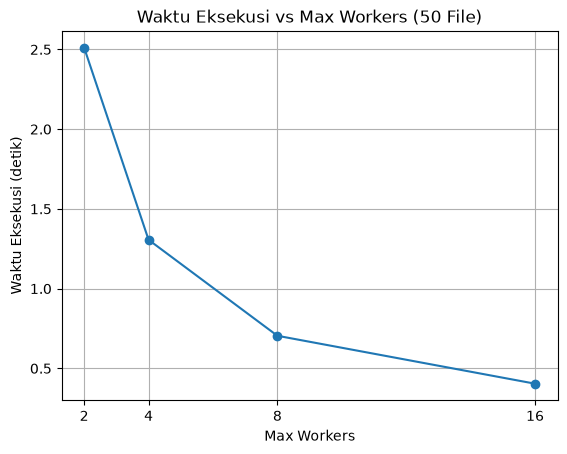

In [9]:
import concurrent.futures
import time
import matplotlib.pyplot as plt

def simulasi_download(file_id):
    time.sleep(0.1)  # Simulasi operasi I/O
    return True

files = list(range(50))
workers_list = [2, 4, 8, 16]
waktu_eksekusi = []

for w in workers_list:
    start_time = time.time()
    with concurrent.futures.ThreadPoolExecutor(max_workers=w) as executor:
        list(executor.map(simulasi_download, files))
    waktu_eksekusi.append(time.time() - start_time)

# Plotting Hasil
plt.plot(workers_list, waktu_eksekusi, marker='o')
plt.title("Waktu Eksekusi vs Max Workers (50 File)")
plt.xlabel("Max Workers")
plt.ylabel("Waktu Eksekusi (detik)")
plt.xticks(workers_list)
plt.grid(True)
plt.show()

 Terdapat 50 file simulasi, di mana setiap file diberi waktu tunggu I/O (time.sleep(0.1)) selama 0,1 detik.
 Max Workers = 2: Thread pool memproses 2 file sekaligus dalam satu waktu. Program membutuhkan 25 gelombang eksekusi (50 dibagi 2) untuk menyelesaikan seluruh file. Total waktu teoritisnya adalah 25 x 0,1 = 2,5 detik.   
 Max Workers = 4: Thread pool memproses 4 file sekaligus. Program membutuhkan 13 gelombang eksekusi (pembulatan ke atas dari 50 dibagi 4 = 12,5). Total waktu teoritisnya adalah 13 x 0,1 = 1,3 detik.   
 Max Workers = 8: Thread pool memproses 8 file sekaligus. Program membutuhkan 7 gelombang eksekusi (pembulatan ke atas dari 50 dibagi 8 = 6,25). Total waktu teoritisnya adalah 7 x 0,1 = 0,7 detik.   
 Max Workers = 16: Thread pool memproses 16 file sekaligus. Program membutuhkan 4 gelombang eksekusi (pembulatan ke atas dari 50 dibagi 16 = 3,125). Total waktu teoritisnya adalah 4 x 0,1 = 0,4 detik.   
 Bentuk kurva pada grafik ini berhasil membuktikan penambahan worker dari 2 ke 4 memberikan pemotongan waktu yang sangat signifikan (menghemat 1,2 detik). Sebaliknya, penambahan jumlah worker dua kali lipat dari 8 ke 16 hanya memangkas waktu yang sangat sedikit (menghemat 0,3 detik). Jika dilanjutkan ke 32 atau 64 worker, waktu eksekusi tidak akan jauh lebih cepat dari 0.5 detik

Penjelasan Kode :

import concurrent.futures, import matplotlib.pyplot as plt: Mengimpor thread pool dan library untuk menggambar grafik.

def simulasi_download(file_id):: Fungsi untuk menyimulasikan proses unduh file (I/O).

time.sleep(0.1): Jeda 0,1 detik bertindak sebagai waktu tunggu server atau jaringan.

files = list(range(50)): Membuat daftar berisi 50 angka yang merepresentasikan 50 tugas/file.

workers_list = [2, 4, 8, 16]: Daftar variasi jumlah thread worker maksimal yang akan diuji.

for w in workers_list:: Menguji masing-masing skenario jumlah worker.

start_time = time.time(): Mencatat waktu mulai eksekusi.

with concurrent.futures.ThreadPoolExecutor(max_workers=w) as executor:: Membuka threadpool yang diatur agar maksimal hanya ada sejumlah w thread berjalan bersamaan. Otomatis menutup pool ketika selesai.

list(executor.map(simulasi_download, files)): Memetakan 50 tugas file ke fungsi simulasi_download untuk dikerjakan secara paralel oleh pool. list() memaksa eksekusi map berjalan hingga selesai.

waktu_eksekusi.append(time.time() - start_time): Menghitung total waktu eksekusi dengan mengurangi waktu saat ini dengan start_time, lalu menyimpannya ke list.

Baris plt.*: Mengonfigurasi dan menampilkan grafik (plot) yang membandingkan jumlah pekerja (sumbu X) dan waktu (sumbu Y).

4. REFLEKSI SINGKAT

Kasus Threading Membantu: Pembuatan skrip Web Scraper yang mengunduh data dari ratusan URL (I/O Bound). Karena program menghabiskan mayoritas waktu untuk menunggu respons dari jaringan (idle), threading dapat mengerjakan request lain saat satu thread sedang menunggu respons.

Kasus Threading Tidak Membantu: Memproses konversi ukuran ribuan file gambar resolusi tinggi (CPU Bound). Python memiliki Global Interpreter Lock (GIL) yang memaksa thread berjalan satu per satu pada satu prosesor. Multiprocessing lebih dibutuhkan di sini agar perhitungan didistribusikan ke berbagai core fisik secara paralel.